In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
df = pd.read_csv("framingham.csv")

df.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [3]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns)

Dataset shape: (4238, 16)

Column names:
Index(['male', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds',
       'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP',
       'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD'],
      dtype='str')


In [4]:
df.isnull().sum()

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

In [6]:
df = df.dropna()

print("Shape after removing missing values:", df.shape)

Shape after removing missing values: (3656, 16)


In [7]:
X = df.drop("TenYearCHD", axis=1).values
y = df["TenYearCHD"].values

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3656, 15)
y shape: (3656,)


In [8]:
print("Class distribution:")
print(pd.Series(y).value_counts())

print("\nClass percentages:")
print(pd.Series(y).value_counts(normalize=True) * 100)

Class distribution:
0    3099
1     557
Name: count, dtype: int64

Class percentages:
0    84.76477
1    15.23523
Name: proportion, dtype: float64


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 2924
Testing samples: 732


In [10]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [11]:
scaler.fit_transform(X_train)

array([[-0.89656277,  1.91721598,  0.02045413, ..., -1.84670699,
         0.59650533,  0.1440002 ],
       [ 1.11537087, -1.22819595,  1.98136806, ..., -1.16562143,
        -1.30015091,  1.67750497],
       [ 1.11537087,  0.86874534,  1.0009111 , ..., -0.09499414,
         0.34911538,  0.31925789],
       ...,
       [-0.89656277,  0.51925513, -0.96000284, ..., -0.47963598,
        -0.6404444 ,  0.05637136],
       [ 1.11537087, -0.64571226,  0.02045413, ..., -0.15379289,
        -0.06320119,  0.36307231],
       [ 1.11537087, -0.29622204, -0.96000284, ...,  0.76248768,
        -0.31059114,  0.05637136]], shape=(2924, 15))

In [12]:
scaler.transform(X_test)

array([[ 1.11537087, -1.11169921,  1.98136806, ...,  2.31085484,
        -0.80537103, -1.17043245],
       [ 1.11537087,  0.51925513,  1.0009111 , ..., -0.04599518,
        -0.06320119, -0.81991708],
       [ 1.11537087,  0.86874534, -0.96000284, ...,  0.36559609,
        -0.55798108, -0.29414402],
       ...,
       [-0.89656277, -0.99520247, -0.96000284, ..., -0.87897751,
         0.18418875, -0.51321612],
       [-0.89656277,  0.40275839,  0.02045413, ...,  1.24512744,
         1.17374853,  0.23162905],
       [-0.89656277,  1.10173882,  1.0009111 , ...,  0.41949495,
         0.34911538,  0.01255694]], shape=(732, 15))

In [13]:
class LogisticRegressionScratch:

    def __init__(self, lr=0.01, epochs=2000):
        self.lr = lr
        self.epochs = epochs
        self.losses = []

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def loss(self, y, y_pred):
        epsilon = 1e-9

        return -np.mean(
            y * np.log(y_pred + epsilon)
            + (1 - y) * np.log(1 - y_pred + epsilon)
        )

    def fit(self, X, y):

        n_samples, n_features = X.shape

        # Initialize weights and bias
        self.weights = np.zeros(n_features)
        self.bias = 0

        for epoch in range(self.epochs):

            # Linear equation
            linear_model = np.dot(X, self.weights) + self.bias

            # Convert to probability
            y_pred = self.sigmoid(linear_model)

            # Calculate loss
            current_loss = self.loss(y, y_pred)
            self.losses.append(current_loss)

            # Calculate gradients
            dw = (1 / n_samples) * np.dot(
                X.T,
                (y_pred - y)
            )

            db = (1 / n_samples) * np.sum(y_pred - y)

            # Update weights and bias
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict_proba(self, X):

        linear_model = np.dot(X, self.weights) + self.bias

        return self.sigmoid(linear_model)

    def predict(self, X, threshold=0.3):

        probabilities = self.predict_proba(X)

        return np.where(probabilities >= threshold, 1, 0)

In [14]:
scratch_model = LogisticRegressionScratch(
    lr=0.01,
    epochs=2000
)

start = time.time()

scratch_model.fit(X_train, y_train)

scratch_time = time.time() - start

print("Training time:", scratch_time, "seconds")

Training time: 0.5286471843719482 seconds


In [15]:
y_pred_scratch = scratch_model.predict(
    X_test,
    threshold=0.3
)

print(y_pred_scratch[:20])

[0 0 1 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0]


In [16]:
scratch_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_scratch),
    "Precision": precision_score(y_test, y_pred_scratch, zero_division=0),
    "Recall": recall_score(y_test, y_pred_scratch, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred_scratch, zero_division=0),
    "Training Time (s)": scratch_time
}

scratch_metrics

{'Accuracy': 0.8087431693989071,
 'Precision': 0.35106382978723405,
 'Recall': 0.29464285714285715,
 'F1 Score': 0.32038834951456313,
 'Training Time (s)': 0.5286471843719482}

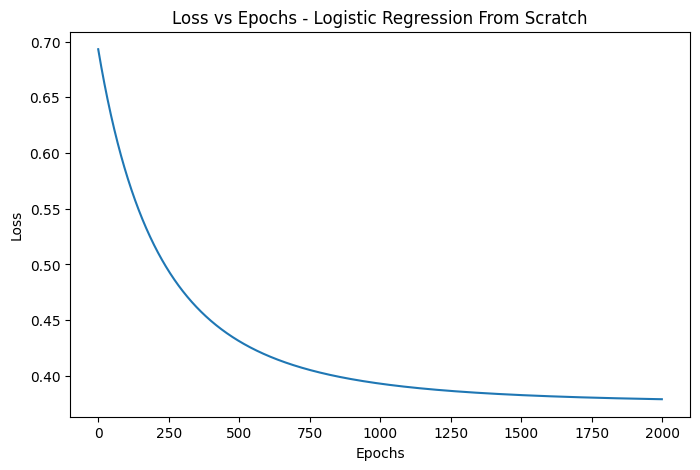

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(scratch_model.losses)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss vs Epochs - Logistic Regression From Scratch")

plt.show()

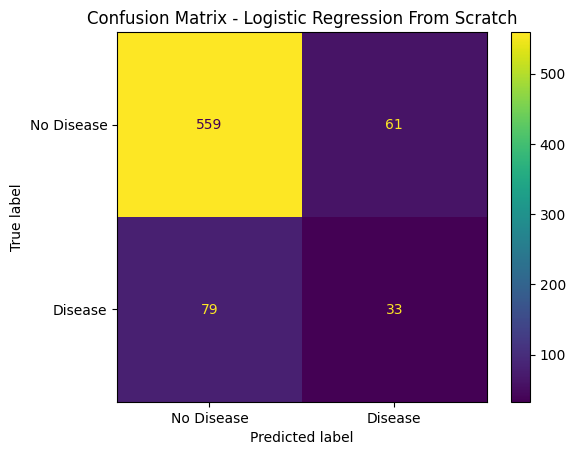

In [18]:
cm_scratch = confusion_matrix(
    y_test,
    y_pred_scratch
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_scratch,
    display_labels=["No Disease", "Disease"]
)

disp.plot()

plt.title("Confusion Matrix - Logistic Regression From Scratch")
plt.show()

In [19]:
sk_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000
)

In [20]:
start = time.time()

sk_model.fit(X_train, y_train)

sk_time = time.time() - start

print("Training time:", sk_time, "seconds")

Training time: 0.047737836837768555 seconds


In [21]:
y_pred_sk = sk_model.predict(X_test)

print(y_pred_sk[:20])

[0 1 1 1 1 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0]


In [22]:
sk_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_sk),
    "Precision": precision_score(y_test, y_pred_sk, zero_division=0),
    "Recall": recall_score(y_test, y_pred_sk, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred_sk, zero_division=0),
    "Training Time (s)": sk_time
}

sk_metrics

{'Accuracy': 0.6926229508196722,
 'Precision': 0.28679245283018867,
 'Recall': 0.6785714285714286,
 'F1 Score': 0.40318302387267907,
 'Training Time (s)': 0.047737836837768555}

In [23]:
comparison = pd.DataFrame(
    [scratch_metrics, sk_metrics],
    index=["From Scratch", "Scikit-learn"]
)

comparison

,Accuracy,Precision,Recall,F1 Score,Training Time (s)
From Scratch,0.808743,0.351064,0.294643,0.320388,0.528647
Scikit-learn,0.692623,0.286792,0.678571,0.403183,0.047738


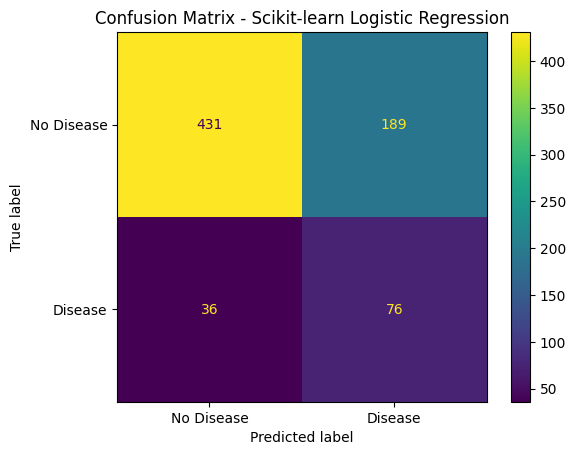

In [24]:
cm_sk = confusion_matrix(
    y_test,
    y_pred_sk
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_sk,
    display_labels=["No Disease", "Disease"]
)

disp.plot()

plt.title("Confusion Matrix - Scikit-learn Logistic Regression")

plt.show()

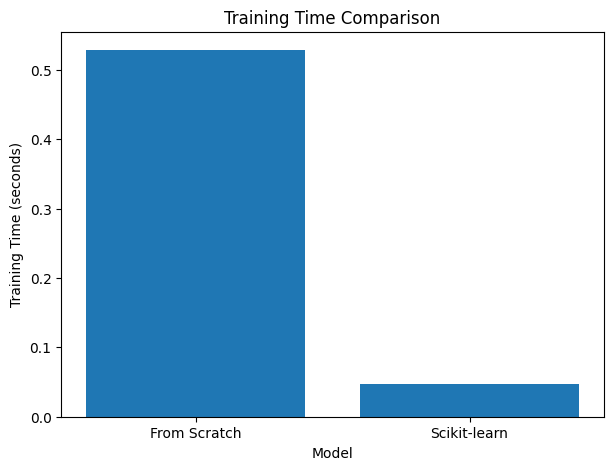

In [25]:
models = ["From Scratch", "Scikit-learn"]
times = [scratch_time, sk_time]

plt.figure(figsize=(7, 5))

plt.bar(models, times)

plt.xlabel("Model")
plt.ylabel("Training Time (seconds)")
plt.title("Training Time Comparison")

plt.show()

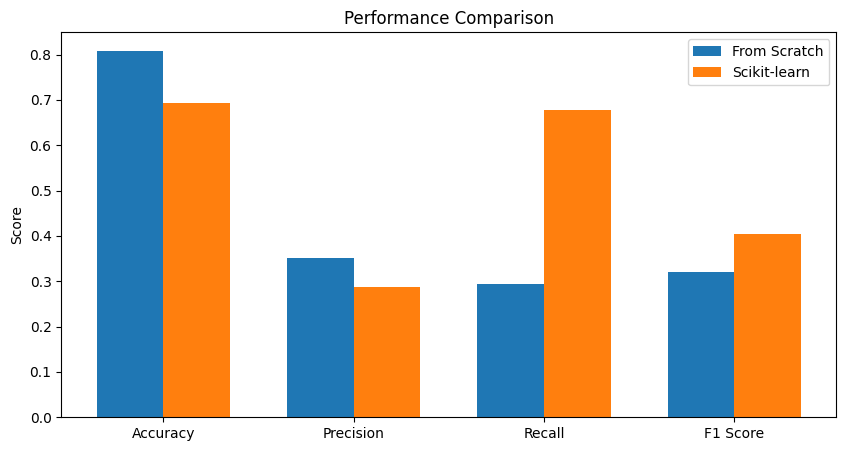

In [26]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

scratch_values = [
    scratch_metrics["Accuracy"],
    scratch_metrics["Precision"],
    scratch_metrics["Recall"],
    scratch_metrics["F1 Score"]
]

sk_values = [
    sk_metrics["Accuracy"],
    sk_metrics["Precision"],
    sk_metrics["Recall"],
    sk_metrics["F1 Score"]
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, scratch_values, width, label="From Scratch")
plt.bar(x + width/2, sk_values, width, label="Scikit-learn")

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("Performance Comparison")
plt.legend()

plt.show()

In [27]:
feature_names = df.drop("TenYearCHD", axis=1).columns

weights = pd.DataFrame({
    "Feature": feature_names,
    "Weight": scratch_model.weights
})

weights

,Feature,Weight
0,male,0.183450
1,age,0.416524
2,education,-0.069650
3,currentSmoker,0.049613
4,cigsPerDay,0.139571
5,BPMeds,0.050305
6,prevalentStroke,0.034762
7,prevalentHyp,0.130213
8,diabetes,0.023223
9,totChol,0.098665


In [28]:
weights.sort_values(
    by="Weight",
    ascending=False
)

,Feature,Weight
1,age,0.416524
10,sysBP,0.233557
0,male,0.183450
14,glucose,0.149613
4,cigsPerDay,0.139571
7,prevalentHyp,0.130213
9,totChol,0.098665
5,BPMeds,0.050305
3,currentSmoker,0.049613
6,prevalentStroke,0.034762


In [29]:
sk_coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": sk_model.coef_[0]
})

sk_coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

,Feature,Coefficient
1,age,0.566677
10,sysBP,0.300031
0,male,0.234302
4,cigsPerDay,0.215008
9,totChol,0.131552
14,glucose,0.129902
7,prevalentHyp,0.126353
5,BPMeds,0.064511
3,currentSmoker,0.055838
12,BMI,0.049876
